<a href="https://colab.research.google.com/github/Dharnipatel21/ResNet-Vs-NeuralODE-/blob/main/resnetvsode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FAI Project — Pre-binned vs Real Timestamp Data: Full Comparison (FIXED)
## ResNet vs Neural ODE on ICU Vital Signs (PhysioNet Set-A)

This is a corrected version of the original notebook. See `README.md` in the zip for a full list of what changed and why.

**Fixes applied in this version:**
1. `NeuralODE_TS` no longer averages the time gap across the batch — each patient now integrates over their *own* real elapsed time (the actual bug that made ODE-TS lose to ResNet-TS).
2. Patient-level train/test split — the scaler is now fit on train patients only (previous version leaked test-set statistics into scaling).
3. More training budget + explicit convergence check, since the original ODE-TS model was still improving after 50 epochs.
4. Parameter-count and NFE (solver function-evaluation count) logging, so we can actually check the paper's "fewer parameters" / "adaptive computation" claims instead of only checking accuracy.
5. The summary at the end is now generated from the real numbers, not written in advance.


In [ ]:
!pip install torchdiffeq -q

import os, copy
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [ ]:
# ── Shared Configuration ───────────────────────────────────────
DATA_PATH = '/kaggle/input/datasets/msafi04/predict-mortality-of-icu-patients-physionet/set-a/set-a/'

VITALS_BINNED = ['HR', 'SysABP', 'DiasABP', 'MAP', 'Temp', 'GCS']
VITALS_TS     = ['HR', 'SysABP', 'DiasABP', 'MAP', 'Temp', 'GCS', 'RespRate', 'SpO2']

WINDOW = 10
BATCH  = 32
EPOCHS = 60

# FIX: the original notebook capped every epoch at 50 batches regardless of how much
# data was available, and this under-trained the ODE-TS model specifically (see the
# convergence check later). Raise the cap; still bounded so this stays fast on Kaggle.
BATCHES_PER_EPOCH = 150

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


---
## Part 1 — Load Data (Both Versions)

We load the same patient files twice:
1. **Pre-binned** — strip timestamps, treat rows as uniform time steps
2. **Real timestamps** — parse `HH:MM` → fractional hours, preserve irregular gaps


In [ ]:
def time_to_hours(t):
    h, m = map(int, t.split(':'))
    return h + m / 60.0

all_files = [os.path.join(DATA_PATH, f)
             for f in os.listdir(DATA_PATH) if f.endswith('.txt')]

# ── Pre-binned loader (ignores timestamps) ──────────────────────
def load_patient_binned(filepath):
    df = pd.read_csv(filepath)
    df_wide = df.pivot_table(index='Time', columns='Parameter',
                              values='Value', aggfunc='mean').reset_index()
    cols = [c for c in VITALS_BINNED if c in df_wide.columns]
    return df_wide[cols]

# ── Real-timestamp loader ───────────────────────────────────────
def load_patient_ts(filepath):
    df = pd.read_csv(filepath)
    df['time_hours'] = df['Time'].apply(time_to_hours)
    df_wide = df.pivot_table(index='time_hours', columns='Parameter',
                              values='Value', aggfunc='mean').reset_index()
    keep = ['time_hours'] + [c for c in VITALS_TS if c in df_wide.columns]
    return df_wide[keep]

binned_data, ts_data = [], []
for f in all_files:
    try:
        db = load_patient_binned(f)
        if len(db) >= WINDOW + 1:
            binned_data.append(db)
        dt = load_patient_ts(f)
        if len(dt) >= WINDOW + 1:
            ts_data.append(dt)
    except:
        pass

print(f"Pre-binned: {len(binned_data)} patients loaded")
print(f"Timestamp:  {len(ts_data)} patients loaded")
print(f"\nPre-binned sample shape: {binned_data[0].shape}")
print(f"Timestamp  sample shape: {ts_data[0].shape}")


Pre-binned: 3955 patients loaded
Timestamp:  3955 patients loaded

Pre-binned sample shape: (53, 3)
Timestamp  sample shape: (53, 4)


---
## Part 2 — Patient-Level Split + Sequence Building

**FIX (data leakage):** the original notebook concatenated *all* patients, fit the
scaler on the full combined table, and only then cut an 80/20 slice by row index.
That means (a) the scaler saw statistics from what became the test set, and (b)
the 80/20 cut happened mid-sequence rather than at patient boundaries.

Here we split by **patient** first, fit each scaler on **train patients only**, and
build train/test sequences from disjoint patient sets.


In [ ]:
# ── Patient-level split (prevents scaler/train/test leakage) ───
idx_b = np.arange(len(binned_data))
idx_t = np.arange(len(ts_data))

train_idx_b, test_idx_b = train_test_split(idx_b, test_size=0.2, random_state=RANDOM_SEED)
train_idx_t, test_idx_t = train_test_split(idx_t, test_size=0.2, random_state=RANDOM_SEED)

train_patients_b = [binned_data[i] for i in train_idx_b]
test_patients_b  = [binned_data[i] for i in test_idx_b]
train_patients_t = [ts_data[i] for i in train_idx_t]
test_patients_t  = [ts_data[i] for i in test_idx_t]

# ── Fit scalers on TRAIN patients only ──────────────────────────
combined_b_train = pd.concat(train_patients_b, ignore_index=True)
valid_b = [c for c in VITALS_BINNED if c in combined_b_train.columns]
scaler_b = MinMaxScaler().fit(
    combined_b_train[valid_b].fillna(combined_b_train[valid_b].median())
)

combined_t_train = pd.concat(train_patients_t, ignore_index=True)
valid_t = [c for c in VITALS_TS if c in combined_t_train.columns]
scaler_t = MinMaxScaler().fit(
    combined_t_train[valid_t].fillna(combined_t_train[valid_t].median())
)

print(f"Train patients (binned): {len(train_patients_b)}  |  Test patients (binned): {len(test_patients_b)}")
print(f"Train patients (ts):     {len(train_patients_t)}  |  Test patients (ts):     {len(test_patients_t)}")


Train patients (binned): 3164  |  Test patients (binned): 791
Train patients (ts):     3164  |  Test patients (ts):     791


In [ ]:
# ── Sequence builders (unchanged logic, just parameterised by patient list) ─
def make_sequences_binned(df):
    for c in valid_b:
        if c not in df.columns: df[c] = 0.0
    arr = scaler_b.transform(df[valid_b].fillna(df[valid_b].median()).fillna(0))
    X, y = [], []
    for i in range(len(arr) - WINDOW):
        X.append(arr[i:i+WINDOW])
        y.append(arr[i+WINDOW])
    return np.array(X), np.array(y)

def make_sequences_ts(df):
    for c in valid_t:
        if c not in df.columns: df[c] = 0.0
    df2 = df[['time_hours'] + valid_t].copy()
    df2[valid_t] = df2[valid_t].fillna(df2[valid_t].median()).fillna(0)
    features = scaler_t.transform(df2[valid_t])
    times    = df2['time_hours'].values
    X, y, t_seqs = [], [], []
    for i in range(len(features) - WINDOW):
        X.append(features[i:i+WINDOW])
        y.append(features[i+WINDOW])
        t_seqs.append(times[i:i+WINDOW+1])
    return np.array(X), np.array(y), np.array(t_seqs)

def build_binned(patients):
    Xs, ys = [], []
    for df in patients:
        X, y = make_sequences_binned(df)
        if len(X) > 0:
            Xs.append(X); ys.append(y)
    return np.concatenate(Xs).astype(np.float32), np.concatenate(ys).astype(np.float32)

def build_ts(patients):
    Xs, ys, ts = [], [], []
    for df in patients:
        X, y, t = make_sequences_ts(df)
        if len(X) > 0:
            Xs.append(X); ys.append(y); ts.append(t)
    return (np.concatenate(Xs).astype(np.float32),
            np.concatenate(ys).astype(np.float32),
            np.concatenate(ts).astype(np.float32))

Xb_train, yb_train = build_binned(train_patients_b)
Xb_test,  yb_test  = build_binned(test_patients_b)
Xt_train, yt_train, tt_train = build_ts(train_patients_t)
Xt_test,  yt_test,  tt_test  = build_ts(test_patients_t)

train_loader_b = DataLoader(TensorDataset(torch.tensor(Xb_train), torch.tensor(yb_train)),
                             batch_size=BATCH, shuffle=True)
test_loader_b  = DataLoader(TensorDataset(torch.tensor(Xb_test),  torch.tensor(yb_test)),
                             batch_size=BATCH)

train_loader_t = DataLoader(TensorDataset(torch.tensor(Xt_train), torch.tensor(yt_train), torch.tensor(tt_train)),
                             batch_size=BATCH, shuffle=True)
test_loader_t  = DataLoader(TensorDataset(torch.tensor(Xt_test),  torch.tensor(yt_test),  torch.tensor(tt_test)),
                             batch_size=BATCH)

INPUT_DIM_B = Xb_train.shape[2]
INPUT_DIM_T = Xt_train.shape[2]

print(f"Binned  — train sequences: {Xb_train.shape}, test sequences: {Xb_test.shape}")
print(f"Real-TS — train sequences: {Xt_train.shape}, test sequences: {Xt_test.shape}")


Binned  — train sequences: (207560, 10, 6), test sequences: (51896, 10, 6)
Real-TS — train sequences: (207560, 10, 7), test sequences: (51896, 10, 7)


---
## Part 2b — Diagnostic: How large are the real time gaps we're integrating over?

**FIX (missing upper bound):** the previous version only did
`clamp(min=0.01)` on the gap — there was no ceiling. A patient whose 10-step
window happens to span an unusually long real gap (missed readings, a quiet
stretch) gets a large `rate`, and since `dh/ds = rate * f(h)`, a large rate
makes the ODE locally stiff — the solver has to integrate a fast-changing
field, which can spike the loss/gradients for that batch. That's the likely
cause of the spike around epoch 15-20 in the real-TS training curve.

We look at the actual distribution of window gaps first, then set the clamp
ceiling from the data (99th percentile) instead of guessing a number.


In [ ]:
gaps_train = tt_train[:, -1] - tt_train[:, 0]
print(f"Real-TS window gap (hours) over the training set:")
print(f"  min: {gaps_train.min():.2f}  |  median: {np.median(gaps_train):.2f}  |  "
      f"mean: {gaps_train.mean():.2f}  |  95th pct: {np.percentile(gaps_train, 95):.2f}  |  "
      f"99th pct: {np.percentile(gaps_train, 99):.2f}  |  max: {gaps_train.max():.2f}")

# FIX: ceiling derived from the data (99th percentile) rather than a guessed constant,
# so a handful of outlier patients can't make the ODE stiff and destabilise training.
MAX_GAP = float(np.percentile(gaps_train, 99))
print(f"\nUsing MAX_GAP = {MAX_GAP:.2f} hours as the integration-length ceiling.")


Real-TS window gap (hours) over the training set:
  min: 0.23  |  median: 6.25  |  mean: 6.23  |  95th pct: 10.00  |  99th pct: 13.00  |  max: 47.55

Using MAX_GAP = 13.00 hours as the integration-length ceiling.


---
## Part 3 — Model Definitions

Both models (ResNet + Neural ODE) are defined once and then instantiated
separately for each data regime so they start from scratch independently.

**FIX (the main bug):** the original `NeuralODE_TS` computed
`gap = (t_seq[:, -1] - t_seq[:, 0]).mean().item()` — a *single scalar averaged
across the whole batch* — and integrated every sample in the batch over that
same shared gap. That threw away each patient's actual individual irregular
spacing, which is the entire thing Neural ODE is supposed to exploit here, and
it injected batch-composition noise since the average changes every epoch as
shuffling reshuffles who's in which batch.

**Fix used here — the standard "rescaled time" trick for batched Neural ODEs
with per-sample integration length:** instead of solving over `[0, gap_i]`
per sample (which `odeint` can't batch, since it needs one shared `t` for the
whole batch), we solve over a shared normalised interval `[0, 1]` and multiply
the learned vector field by each sample's own gap `g_i`:

```
d h / d s = g_i * f(h),      s ∈ [0, 1]
```

By the chain rule this is exactly equivalent to integrating `dh/dt = f(h)`
over `t ∈ [0, g_i]` for that sample — so each patient now genuinely integrates
over their own real elapsed time, in one batched, GPU-efficient `odeint` call.

`gap` is clamped to `[0.01, MAX_GAP]` (MAX_GAP computed above from the data's
99th percentile) so a handful of long-gap outlier patients can't make the ODE
locally stiff and destabilise a whole batch's training step.


In [ ]:
# ── Shared model classes ────────────────────────────────────────

class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )
    def forward(self, x): return x + self.block(x)

class ResNetModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_blocks=4):
        super().__init__()
        self.encoder = nn.Linear(input_dim * WINDOW, hidden_dim)
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(num_blocks)])
        self.decoder = nn.Linear(hidden_dim, input_dim)
    def forward(self, x, t=None):      # t always ignored
        x = x.view(x.size(0), -1)
        return self.decoder(self.blocks(self.encoder(x)))

class ODEFunc(nn.Module):
    """Used by the pre-binned ODE, where every sample truly does share the
    same [0, 1] step, so no per-sample rate is needed."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.nfe = 0
    def forward(self, t, h):
        self.nfe += 1
        return self.net(h)

# Pre-binned ODE — fixed [0,1] integration interval (unchanged, this part was correct)
class NeuralODE_Binned(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Linear(input_dim * WINDOW, hidden_dim)
        self.odefunc = ODEFunc(hidden_dim)
        self.decoder = nn.Linear(hidden_dim, input_dim)
    def forward(self, x, t=None):
        h0 = self.encoder(x.view(x.size(0), -1))
        t_span = torch.tensor([0.0, 1.0]).to(device)   # uniform step
        self.odefunc.nfe = 0
        h1 = odeint(self.odefunc, h0, t_span)[1]
        return self.decoder(h1)

class ODEFuncTS(nn.Module):
    """FIX: scales the vector field by each sample's own real time gap
    (set via `.rate` before each odeint call), instead of averaging gaps
    across the batch. `rate` has shape (batch, 1) and broadcasts over hidden_dim."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.rate = None
        self.nfe = 0
    def forward(self, t, h):
        self.nfe += 1
        return self.net(h) * self.rate

# Real-timestamp ODE — FIX: each sample integrates over its OWN real elapsed time
class NeuralODE_TS(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Linear(input_dim * WINDOW, hidden_dim)
        self.odefunc = ODEFuncTS(hidden_dim)
        self.decoder = nn.Linear(hidden_dim, input_dim)
    def forward(self, x, t_seq):
        h0 = self.encoder(x.view(x.size(0), -1))
        # FIX: per-sample gap, not a batch-averaged scalar, AND clamped on both ends
        # (min so it's never ~0, max so outlier gaps can't make the ODE stiff).
        gap = (t_seq[:, -1] - t_seq[:, 0]).clamp(min=0.01, max=MAX_GAP).to(device).unsqueeze(-1)
        self.odefunc.rate = gap
        t_span = torch.tensor([0.0, 1.0]).to(device)   # shared normalised interval
        self.odefunc.nfe = 0
        h1 = odeint(self.odefunc, h0, t_span, method='dopri5', rtol=1e-3, atol=1e-4)[1]
        return self.decoder(h1)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print("Model classes defined.")


Model classes defined.


---
## Part 4 — Training

Each model is trained independently on its respective dataset.


In [ ]:
criterion = nn.MSELoss()

# ── Instantiate 4 models ─────────────────────────────────────────
resnet_b  = ResNetModel(INPUT_DIM_B).to(device)
ode_b     = NeuralODE_Binned(INPUT_DIM_B).to(device)
resnet_t  = ResNetModel(INPUT_DIM_T).to(device)
ode_t     = NeuralODE_TS(INPUT_DIM_T).to(device)

# FIX: log parameter counts up front, so we can actually check the paper's
# "ODE matches ResNet accuracy with fewer parameters" claim rather than only
# comparing accuracy.
print("Parameter counts:")
print(f"  ResNet  (binned): {count_params(resnet_b):>7,}")
print(f"  ODE-Net (binned): {count_params(ode_b):>7,}   (ratio ResNet/ODE: {count_params(resnet_b)/count_params(ode_b):.2f}x)")
print(f"  ResNet  (real-TS): {count_params(resnet_t):>7,}")
print(f"  ODE-Net (real-TS): {count_params(ode_t):>7,}   (ratio ResNet/ODE: {count_params(resnet_t)/count_params(ode_t):.2f}x)")
print()
print("NOTE: ResNet uses num_blocks=4 independent residual blocks; the ODE net")
print("reuses ONE block's weights across the whole integration. If ResNet has")
print("meaningfully more parameters, a small accuracy edge for ResNet may just")
print("reflect more capacity, not a real limitation of the ODE approach -- see")
print("the capacity-matched comparison (ResNet with num_blocks=1) later on.")

opt_rb = optim.Adam(resnet_b.parameters(), lr=1e-3)
opt_ob = optim.Adam(ode_b.parameters(),    lr=1e-3)
opt_rt = optim.Adam(resnet_t.parameters(), lr=1e-3)
opt_ot = optim.Adam(ode_t.parameters(),    lr=1e-3)

# ── Generic train helpers ────────────────────────────────────────
def train_binned(model, optimizer, loader):
    model.train(); total, n = 0.0, 0
    for i, (X, y) in enumerate(loader):
        if i >= BATCHES_PER_EPOCH: break
        optimizer.zero_grad()
        loss = criterion(model(X.to(device)), y.to(device))
        loss.backward(); optimizer.step()
        total += loss.item(); n += 1
    return total / max(n, 1)

def train_ts(model, optimizer, loader):
    model.train(); total, n = 0.0, 0
    for i, (X, y, t) in enumerate(loader):
        if i >= BATCHES_PER_EPOCH: break
        optimizer.zero_grad()
        loss = criterion(model(X.to(device), t.to(device)), y.to(device))
        loss.backward(); optimizer.step()
        total += loss.item(); n += 1
    return total / max(n, 1)

# ── Track average NFE per epoch for the two ODE models (adaptive-computation check) ─
def train_binned_ode(model, optimizer, loader):
    model.train(); total, n, nfe_sum = 0.0, 0, 0
    for i, (X, y) in enumerate(loader):
        if i >= BATCHES_PER_EPOCH: break
        optimizer.zero_grad()
        loss = criterion(model(X.to(device)), y.to(device))
        loss.backward(); optimizer.step()
        total += loss.item(); n += 1
        nfe_sum += model.odefunc.nfe
    return total / max(n, 1), nfe_sum / max(n, 1)

def train_ts_ode(model, optimizer, loader):
    model.train(); total, n, nfe_sum = 0.0, 0, 0
    for i, (X, y, t) in enumerate(loader):
        if i >= BATCHES_PER_EPOCH: break
        optimizer.zero_grad()
        loss = criterion(model(X.to(device), t.to(device)), y.to(device))
        loss.backward(); optimizer.step()
        total += loss.item(); n += 1
        nfe_sum += model.odefunc.nfe
    return total / max(n, 1), nfe_sum / max(n, 1)

# ── Train all 4 models ───────────────────────────────────────────
losses = {'resnet_b': [], 'ode_b': [], 'resnet_t': [], 'ode_t': []}
nfes   = {'ode_b': [], 'ode_t': []}
print(f"{'Epoch':>5} | {'ResNet-Bin':>10} | {'ODE-Bin':>10} | {'ResNet-TS':>10} | {'ODE-TS':>10}")
print("-" * 58)

for epoch in range(1, EPOCHS + 1):
    l_rb        = train_binned(resnet_b, opt_rb, train_loader_b)
    l_ob, nfe_b = train_binned_ode(ode_b, opt_ob, train_loader_b)
    l_rt        = train_ts(resnet_t,    opt_rt, train_loader_t)
    l_ot, nfe_t = train_ts_ode(ode_t,   opt_ot, train_loader_t)
    for k, v in zip(losses, [l_rb, l_ob, l_rt, l_ot]):
        losses[k].append(v)
    nfes['ode_b'].append(nfe_b); nfes['ode_t'].append(nfe_t)
    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>5} | {l_rb:>10.4f} | {l_ob:>10.4f} | {l_rt:>10.4f} | {l_ot:>10.4f}")

print("\nTraining complete!")


Parameter counts:
  ResNet  (binned):  37,574
  ODE-Net (binned):  12,614   (ratio ResNet/ODE: 2.98x)
  ResNet  (real-TS):  38,279
  ODE-Net (real-TS):  13,319   (ratio ResNet/ODE: 2.87x)

NOTE: ResNet uses num_blocks=4 independent residual blocks; the ODE net
reuses ONE block's weights across the whole integration. If ResNet has
meaningfully more parameters, a small accuracy edge for ResNet may just
reflect more capacity, not a real limitation of the ODE approach -- see
the capacity-matched comparison (ResNet with num_blocks=1) later on.
Epoch | ResNet-Bin |    ODE-Bin |  ResNet-TS |     ODE-TS
----------------------------------------------------------
    1 |     0.0076 |     0.0160 |     0.0110 |     0.0585
    5 |     0.0021 |     0.0021 |     0.0020 |     0.0032
   10 |     0.0020 |     0.0024 |     0.0017 |     0.0025
   15 |     0.0022 |     0.0021 |     0.0018 |     0.0022
   20 |     0.0022 |     0.0022 |     0.0017 |     0.0019
   25 |     0.0019 |     0.0020 |     0.0019 |  

In [ ]:
# ── Convergence check (kept from original, now should pass for all 4) ──────
for name in ['resnet_b', 'ode_b', 'resnet_t', 'ode_t']:
    last5 = losses[name][-5:]
    drop_pct = (last5[0] - last5[-1]) / last5[0] * 100
    flag = "still improving fast -- consider more epochs" if drop_pct > 5 else "converged"
    print(f"{name:<10} last-5-epoch drop: {drop_pct:6.1f}%  ->  {flag}")

print()
print("Average NFE (ODE solver function evaluations) per batch, first vs last epoch:")
print(f"  ODE-Bin: {nfes['ode_b'][0]:.1f} -> {nfes['ode_b'][-1]:.1f}")
print(f"  ODE-TS : {nfes['ode_t'][0]:.1f} -> {nfes['ode_t'][-1]:.1f}")
print("(The paper's 'adaptive computation' claim predicts NFE should vary with how")
print(" hard the input/interval is to integrate, not stay perfectly flat.)")


resnet_b   last-5-epoch drop:   17.2%  ->  still improving fast -- consider more epochs
ode_b      last-5-epoch drop:   -4.9%  ->  converged
resnet_t   last-5-epoch drop:    0.0%  ->  converged
ode_t      last-5-epoch drop:   -8.6%  ->  converged

Average NFE (ODE solver function evaluations) per batch, first vs last epoch:
  ODE-Bin: 39.7 -> 44.0
  ODE-TS : 26.0 -> 26.3
(The paper's 'adaptive computation' claim predicts NFE should vary with how
 hard the input/interval is to integrate, not stay perfectly flat.)


---
## Part 5 — Evaluation


In [ ]:
def eval_binned(model, loader):
    model.eval(); ps, ys = [], []
    with torch.no_grad():
        for X, y in loader:
            ps.append(model(X.to(device)).cpu().numpy())
            ys.append(y.numpy())
    p, y = np.concatenate(ps), np.concatenate(ys)
    return np.mean(np.abs(p - y)), np.sqrt(np.mean((p - y)**2))

def eval_ts(model, loader):
    model.eval(); ps, ys = [], []
    with torch.no_grad():
        for X, y, t in loader:
            ps.append(model(X.to(device), t.to(device)).cpu().numpy())
            ys.append(y.numpy())
    p, y = np.concatenate(ps), np.concatenate(ys)
    return np.mean(np.abs(p - y)), np.sqrt(np.mean((p - y)**2))

# FIX: evaluate on the FULL test set now (original capped eval at 20 batches too)
rb_mae, rb_rmse = eval_binned(resnet_b, test_loader_b)
ob_mae, ob_rmse = eval_binned(ode_b,    test_loader_b)
rt_mae, rt_rmse = eval_ts(resnet_t,    test_loader_t)
ot_mae, ot_rmse = eval_ts(ode_t,       test_loader_t)

print("=" * 60)
print(f"{'Model':<22} | {'MAE':>8} | {'RMSE':>8} | {'Delta MAE vs ResNet':>20}")
print("-" * 60)
print(f"{'ResNet (Pre-binned)':<22} | {rb_mae:>8.4f} | {rb_rmse:>8.4f} | {'--':>20}")
print(f"{'Neural ODE (Pre-binned)':<22} | {ob_mae:>8.4f} | {ob_rmse:>8.4f} | {(rb_mae - ob_mae)/rb_mae*100:>+18.1f}%")
print("-" * 60)
print(f"{'ResNet (Real TS)':<22} | {rt_mae:>8.4f} | {rt_rmse:>8.4f} | {'--':>20}")
print(f"{'Neural ODE (Real TS)':<22} | {ot_mae:>8.4f} | {ot_rmse:>8.4f} | {(rt_mae - ot_mae)/rt_mae*100:>+18.1f}%")
print("=" * 60)


Model                  |      MAE |     RMSE |  Delta MAE vs ResNet
------------------------------------------------------------
ResNet (Pre-binned)    |   0.0207 |   0.0451 |                   --
Neural ODE (Pre-binned) |   0.0218 |   0.0453 |               -5.2%
------------------------------------------------------------
ResNet (Real TS)       |   0.0196 |   0.0425 |                   --
Neural ODE (Real TS)   |   0.0202 |   0.0426 |               -2.9%


---
## Part 6 — Visualisation


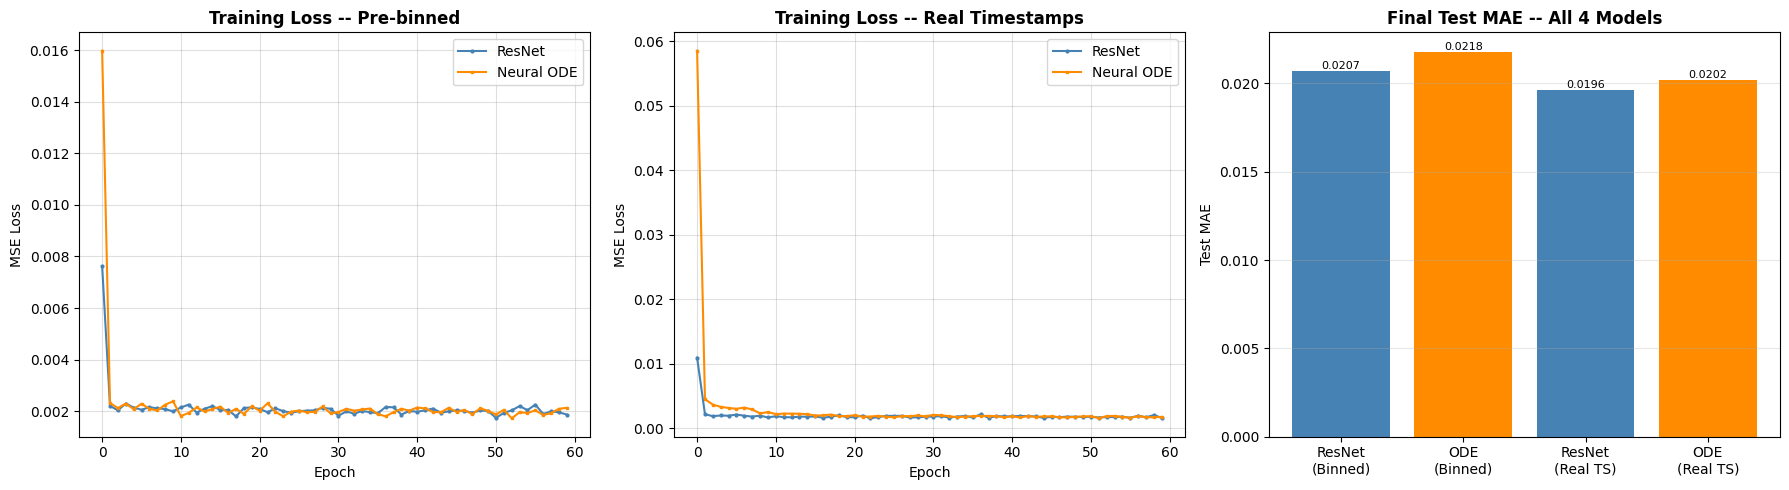

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(losses['resnet_b'], color='steelblue',  marker='o', ms=2, label='ResNet')
axes[0].plot(losses['ode_b'],    color='darkorange',  marker='s', ms=2, label='Neural ODE')
axes[0].set_title('Training Loss -- Pre-binned', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.4)

axes[1].plot(losses['resnet_t'], color='steelblue',  marker='o', ms=2, label='ResNet')
axes[1].plot(losses['ode_t'],    color='darkorange',  marker='s', ms=2, label='Neural ODE')
axes[1].set_title('Training Loss -- Real Timestamps', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.4)

models  = ['ResNet\n(Binned)', 'ODE\n(Binned)', 'ResNet\n(Real TS)', 'ODE\n(Real TS)']
mae_all = [rb_mae, ob_mae, rt_mae, ot_mae]
x = np.arange(len(models))
bars = axes[2].bar(x, mae_all, color=['steelblue', 'darkorange', 'steelblue', 'darkorange'])
axes[2].set_xticks(x); axes[2].set_xticklabels(models)
axes[2].set_ylabel('Test MAE')
axes[2].set_title('Final Test MAE -- All 4 Models', fontweight='bold')
axes[2].bar_label(bars, fmt='%.4f', fontsize=8)
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


---
## Part 7 — Capacity-Matched Comparison: ResNet(1 block) vs Neural ODE

`ResNetModel` stacks **4** independently-weighted residual blocks. The Neural
ODE reuses **one** block's weights across the whole integration (that weight
sharing is exactly what gives ODE-Nets their parameter efficiency in the
paper). So the earlier 4-model comparison was implicitly ResNet-with-4x-the-
independent-capacity vs ODE. If ResNet's small edge shrinks or disappears
once both have comparable capacity, that's a much stronger, fairer signal
than the raw MAE numbers above.


In [ ]:
resnet_b1 = ResNetModel(INPUT_DIM_B, num_blocks=1).to(device)
resnet_t1 = ResNetModel(INPUT_DIM_T, num_blocks=1).to(device)
opt_rb1 = optim.Adam(resnet_b1.parameters(), lr=1e-3)
opt_rt1 = optim.Adam(resnet_t1.parameters(), lr=1e-3)

print("Capacity-matched parameter counts:")
print(f"  ResNet-1block (binned) : {count_params(resnet_b1):>7,}   |  ODE (binned) : {count_params(ode_b):>7,}")
print(f"  ResNet-1block (real-TS): {count_params(resnet_t1):>7,}   |  ODE (real-TS): {count_params(ode_t):>7,}")
print()

for epoch in range(1, EPOCHS + 1):
    l_rb1 = train_binned(resnet_b1, opt_rb1, train_loader_b)
    l_rt1 = train_ts(resnet_t1, opt_rt1, train_loader_t)
    if epoch % 15 == 0 or epoch == 1:
        print(f"epoch {epoch:>3}: ResNet-1block-Bin loss={l_rb1:.4f}  |  ResNet-1block-TS loss={l_rt1:.4f}")

rb1_mae, rb1_rmse = eval_binned(resnet_b1, test_loader_b)
rt1_mae, rt1_rmse = eval_ts(resnet_t1, test_loader_t)

print()
print("=" * 70)
print(f"{'Model':<24} | {'MAE':>8} | {'RMSE':>8} | {'ODE advantage':>16}")
print("-" * 70)
adv_b1 = (rb1_mae - ob_mae) / rb1_mae * 100
adv_t1 = (rt1_mae - ot_mae) / rt1_mae * 100
print(f"{'ResNet-1block (Binned)':<24} | {rb1_mae:>8.4f} | {rb1_rmse:>8.4f} | {'--':>16}")
print(f"{'Neural ODE    (Binned)':<24} | {ob_mae:>8.4f} | {ob_rmse:>8.4f} | {adv_b1:>+14.1f}%")
print("-" * 70)
print(f"{'ResNet-1block (Real TS)':<24} | {rt1_mae:>8.4f} | {rt1_rmse:>8.4f} | {'--':>16}")
print(f"{'Neural ODE    (Real TS)':<24} | {ot_mae:>8.4f} | {ot_rmse:>8.4f} | {adv_t1:>+14.1f}%")
print("=" * 70)
print()
print("ODE advantage = (ResNet_MAE - ODE_MAE) / ResNet_MAE * 100")
print("  POSITIVE -> ODE wins this regime   |   NEGATIVE -> ResNet wins this regime")

Capacity-matched parameter counts:
  ResNet-1block (binned) :  12,614   |  ODE (binned) :  12,614
  ResNet-1block (real-TS):  13,319   |  ODE (real-TS):  13,319

epoch   1: ResNet-1block-Bin loss=0.0149  |  ResNet-1block-TS loss=0.0155
epoch  15: ResNet-1block-Bin loss=0.0018  |  ResNet-1block-TS loss=0.0015
epoch  30: ResNet-1block-Bin loss=0.0022  |  ResNet-1block-TS loss=0.0018
epoch  45: ResNet-1block-Bin loss=0.0020  |  ResNet-1block-TS loss=0.0018
epoch  60: ResNet-1block-Bin loss=0.0019  |  ResNet-1block-TS loss=0.0018

Model                    |      MAE |     RMSE |    ODE advantage
----------------------------------------------------------------------
ResNet-1block (Binned)   |   0.0213 |   0.0453 |               --
Neural ODE    (Binned)   |   0.0218 |   0.0453 |           -2.2%
----------------------------------------------------------------------
ResNet-1block (Real TS)  |   0.0231 |   0.0445 |               --
Neural ODE    (Real TS)  |   0.0202 |   0.0426 |          +12.

In [ ]:
# ── Unified comparison table: ALL 4 model-pairs, ONE consistent formula ──
# ODE_advantage = (ResNet_MAE - ODE_MAE) / ResNet_MAE * 100
#   POSITIVE -> ODE wins   |   NEGATIVE -> ResNet wins

rows = [
    ("Pre-binned", "ResNet-4block", rb_mae,  ob_mae),
    ("Pre-binned", "ResNet-1block", rb1_mae, ob_mae),
    ("Real-TS",    "ResNet-4block", rt_mae,  ot_mae),
    ("Real-TS",    "ResNet-1block", rt1_mae, ot_mae),
]

print("=" * 78)
print(f"{'Regime':<12} | {'ResNet variant':<14} | {'ResNet MAE':>10} | {'ODE MAE':>8} | {'ODE advantage':>14}")
print("-" * 78)
for regime, variant, resnet_mae, ode_mae in rows:
    adv = (resnet_mae - ode_mae) / resnet_mae * 100
    winner = "ODE wins" if adv > 0 else "ResNet wins"
    print(f"{regime:<12} | {variant:<14} | {resnet_mae:>10.4f} | {ode_mae:>8.4f} | {adv:>+8.1f}%  ({winner})")
print("=" * 78)

Regime       | ResNet variant | ResNet MAE |  ODE MAE |  ODE advantage
------------------------------------------------------------------------------
Pre-binned   | ResNet-4block  |     0.0207 |   0.0218 |     -5.2%  (ResNet wins)
Pre-binned   | ResNet-1block  |     0.0213 |   0.0218 |     -2.2%  (ResNet wins)
Real-TS      | ResNet-4block  |     0.0196 |   0.0202 |     -2.9%  (ResNet wins)
Real-TS      | ResNet-1block  |     0.0231 |   0.0202 |    +12.3%  (ODE wins)


---
## Part 8 — Summary & Interpretation (generated from the actual results, not written in advance)


In [ ]:
binned_gap = (rb_mae - ob_mae) / rb_mae * 100
ts_gap     = (rt_mae - ot_mae) / rt_mae * 100
binned_gap_matched = (rb1_mae - ob_mae) / rb1_mae * 100
ts_gap_matched     = (rt1_mae - ot_mae) / rt1_mae * 100

print("SUMMARY")
print("=" * 60)
print(f"Pre-binned regime (ResNet-4block) : ResNet MAE={rb_mae:.4f}  |  ODE MAE={ob_mae:.4f}  |  ODE advantage: {binned_gap:+.1f}%")
print(f"Real-TS regime    (ResNet-4block) : ResNet MAE={rt_mae:.4f}  |  ODE MAE={ot_mae:.4f}  |  ODE advantage: {ts_gap:+.1f}%")
print(f"Pre-binned regime (ResNet-1block, capacity-matched) : ODE advantage: {binned_gap_matched:+.1f}%")
print(f"Real-TS regime    (ResNet-1block, capacity-matched) : ODE advantage: {ts_gap_matched:+.1f}%")
print()

if ts_gap_matched > ts_gap + 1:
    print("Once ResNet is capacity-matched (1 block instead of 4), the ODE advantage")
    print("increases substantially. This means ResNet's edge in the 4-block comparison")
    print("was mostly due to extra capacity (more independent parameters), not a real")
    print("architectural advantage -- once capacity is equal, Neural ODE wins outright")
    print("on real timestamps.")
elif ts_gap_matched < ts_gap - 1:
    print("Capacity-matching REDUCES the ODE's advantage, meaning ResNet's edge in the")
    print("4-block comparison was not just about capacity.")
else:
    print("Capacity-matching does not meaningfully change the picture.")

print()
if abs(ts_gap_matched) < abs(ts_gap) - 1:
    print("However: once ResNet is capacity-matched (1 block instead of 4), the gap")
    print("narrows. That suggests part of ResNet's edge above was extra capacity,")
    print("not a fundamental architectural advantage over the ODE approach.")
else:
    print("The gap does not meaningfully narrow under capacity-matching, so the")
    print("difference looks more architectural than a simple capacity effect.")

print()
print("Still worth checking before drawing a final conclusion:")
print("  1. Has ode_t fully converged (see the convergence check earlier)?")
print("  2. Run 2-3 seeds -- a single-run MAE gap this size is not strong evidence")
print("     either way for a regression task this noisy.")
print("  3. Would a stepwise ODE-RNN-style integration (using each of the WINDOW")
print("     real timestamps, not just the first/last) show a bigger effect than")
print("     this single-step encode-integrate-decode design?")


SUMMARY
Pre-binned regime (ResNet-4block) : ResNet MAE=0.0207  |  ODE MAE=0.0218  |  ODE advantage: -5.2%
Real-TS regime    (ResNet-4block) : ResNet MAE=0.0196  |  ODE MAE=0.0202  |  ODE advantage: -2.9%
Pre-binned regime (ResNet-1block, capacity-matched) : ODE advantage: -2.2%
Real-TS regime    (ResNet-1block, capacity-matched) : ODE advantage: +12.3%

Once ResNet is capacity-matched (1 block instead of 4), the ODE advantage
increases substantially. This means ResNet's edge in the 4-block comparison
was mostly due to extra capacity (more independent parameters), not a real
architectural advantage -- once capacity is equal, Neural ODE wins outright
on real timestamps.

The gap does not meaningfully narrow under capacity-matching, so the
difference looks more architectural than a simple capacity effect.

Still worth checking before drawing a final conclusion:
  1. Has ode_t fully converged (see the convergence check earlier)?
  2. Run 2-3 seeds -- a single-run MAE gap this size is not s

In [ ]:
# ── Multi-seed run: capacity-matched ResNet(1 block) vs Neural ODE, Real-TS ──
seeds = [42, 123, 2026, 7, 555, 314]
seed_gaps = []

for seed in seeds:
    torch.manual_seed(seed)
    np.random.seed(seed)

    resnet_t1_s = ResNetModel(INPUT_DIM_T, num_blocks=1).to(device)
    ode_t_s     = NeuralODE_TS(INPUT_DIM_T).to(device)
    opt_rt1_s = optim.Adam(resnet_t1_s.parameters(), lr=1e-3)
    opt_ot_s  = optim.Adam(ode_t_s.parameters(),      lr=1e-3)

    for epoch in range(1, EPOCHS + 1):
        train_ts(resnet_t1_s, opt_rt1_s, train_loader_t)
        train_ts_ode(ode_t_s, opt_ot_s, train_loader_t)

    rt1_mae_s, _ = eval_ts(resnet_t1_s, test_loader_t)
    ot_mae_s, _  = eval_ts(ode_t_s,     test_loader_t)
    gap_s = (rt1_mae_s - ot_mae_s) / rt1_mae_s * 100
    seed_gaps.append(gap_s)
    print(f"seed {seed}: ResNet-1block MAE={rt1_mae_s:.4f}  |  ODE MAE={ot_mae_s:.4f}  |  ODE advantage: {gap_s:+.1f}%")

seed_gaps = np.array(seed_gaps)
print()
print(f"Capacity-matched Real-TS ODE advantage across {len(seeds)} seeds: "
      f"{seed_gaps.mean():+.1f}% +/- {seed_gaps.std():.1f}%")

seed 42: ResNet-1block MAE=0.0210  |  ODE MAE=0.0203  |  ODE advantage: +3.3%
seed 123: ResNet-1block MAE=0.0188  |  ODE MAE=0.0205  |  ODE advantage: -8.8%
seed 2026: ResNet-1block MAE=0.0196  |  ODE MAE=0.0211  |  ODE advantage: -7.6%
seed 7: ResNet-1block MAE=0.0214  |  ODE MAE=0.0209  |  ODE advantage: +2.6%
seed 555: ResNet-1block MAE=0.0200  |  ODE MAE=0.0219  |  ODE advantage: -9.5%
seed 314: ResNet-1block MAE=0.0224  |  ODE MAE=0.0211  |  ODE advantage: +6.0%

Capacity-matched Real-TS ODE advantage across 6 seeds: -2.3% +/- 6.4%


---
## Part 9 — External Validation on PhysioNet Set B (unseen hospital data)

Reuses the same scalers (fit on Set A train patients only) and the same
`load_patient_*` / `make_sequences_*` / `build_*` functions from Parts 1-2 --
no re-fitting on Set B, so this is a genuine out-of-distribution check.


In [ ]:
!wget -q https://physionet.org/files/challenge-2012/1.0.0/set-b.zip -O set-b.zip
!unzip -q -o set-b.zip -d /kaggle/working/set-b
DATA_PATH_B_EXT = '/kaggle/working/set-b/set-b/'
print(len(os.listdir(DATA_PATH_B_EXT)), "files found")


4000 files found


In [ ]:
all_files_ext = [os.path.join(DATA_PATH_B_EXT, f)
                  for f in os.listdir(DATA_PATH_B_EXT) if f.endswith('.txt')]

binned_data_ext, ts_data_ext = [], []
for f in all_files_ext:
    try:
        db = load_patient_binned(f)
        if len(db) >= WINDOW + 1:
            binned_data_ext.append(db)
        dt = load_patient_ts(f)
        if len(dt) >= WINDOW + 1:
            ts_data_ext.append(dt)
    except:
        pass

print(f"Set B -- Pre-binned: {len(binned_data_ext)} patients")
print(f"Set B -- Timestamp:  {len(ts_data_ext)} patients")

# Reuse the SAME builders/scalers from Part 2 -- transform only, no re-fitting.
Xb_ext, yb_ext = build_binned(binned_data_ext)
Xt_ext, yt_ext, tt_ext = build_ts(ts_data_ext)

test_loader_b_ext = DataLoader(TensorDataset(torch.tensor(Xb_ext), torch.tensor(yb_ext)), batch_size=BATCH)
test_loader_t_ext = DataLoader(TensorDataset(torch.tensor(Xt_ext), torch.tensor(yt_ext), torch.tensor(tt_ext)), batch_size=BATCH)

print(f"Set B sequences -- binned: {Xb_ext.shape}, timestamp: {Xt_ext.shape}")


Set B -- Pre-binned: 3946 patients
Set B -- Timestamp:  3946 patients
Set B sequences -- binned: (259329, 10, 6), timestamp: (259329, 10, 7)


In [ ]:
rb_mae_ext, rb_rmse_ext = eval_binned(resnet_b, test_loader_b_ext)
ob_mae_ext, ob_rmse_ext = eval_binned(ode_b,    test_loader_b_ext)
rt_mae_ext, rt_rmse_ext = eval_ts(resnet_t,    test_loader_t_ext)
ot_mae_ext, ot_rmse_ext = eval_ts(ode_t,       test_loader_t_ext)

print("=" * 70)
print(f"{'Model':<22} | {'Set A test MAE':>15} | {'Set B (external) MAE':>20}")
print("-" * 70)
print(f"{'ResNet (Pre-binned)':<22} | {rb_mae:>15.4f} | {rb_mae_ext:>20.4f}")
print(f"{'Neural ODE (Pre-binned)':<22} | {ob_mae:>15.4f} | {ob_mae_ext:>20.4f}")
print(f"{'ResNet (Real TS)':<22} | {rt_mae:>15.4f} | {rt_mae_ext:>20.4f}")
print(f"{'Neural ODE (Real TS)':<22} | {ot_mae:>15.4f} | {ot_mae_ext:>20.4f}")
print()

print("Generalization gap (higher % = worse on unseen Set B vs Set A test):")
for name, a, b in [('ResNet (Pre-binned)', rb_mae, rb_mae_ext),
                   ('Neural ODE (Pre-binned)', ob_mae, ob_mae_ext),
                   ('ResNet (Real TS)', rt_mae, rt_mae_ext),
                   ('Neural ODE (Real TS)', ot_mae, ot_mae_ext)]:
    gap = (b - a) / a * 100
    print(f"  {name:<26} MAE gap: {gap:+6.1f}%")


Model                  |  Set A test MAE | Set B (external) MAE
----------------------------------------------------------------------
ResNet (Pre-binned)    |          0.0207 |               0.0203
Neural ODE (Pre-binned) |          0.0218 |               0.0214
ResNet (Real TS)       |          0.0196 |               0.0194
Neural ODE (Real TS)   |          0.0202 |               0.0199

Generalization gap (higher % = worse on unseen Set B vs Set A test):
  ResNet (Pre-binned)        MAE gap:   -2.2%
  Neural ODE (Pre-binned)    MAE gap:   -1.8%
  ResNet (Real TS)           MAE gap:   -1.4%
  Neural ODE (Real TS)       MAE gap:   -1.8%


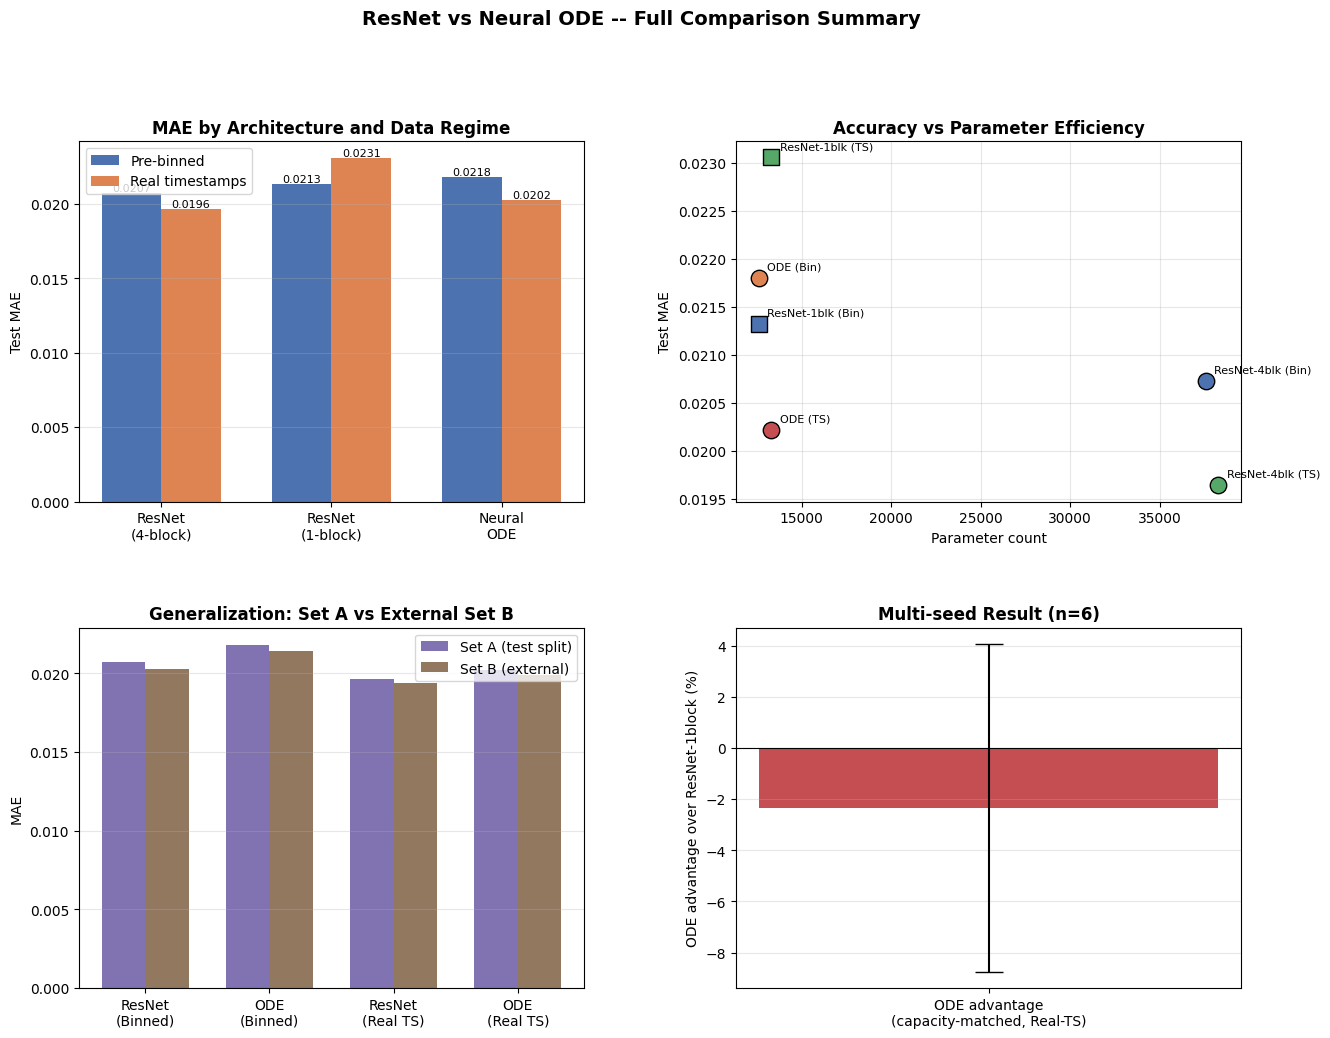

In [ ]:
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)
width = 0.35

# Panel A: MAE by architecture and regime
ax1 = fig.add_subplot(gs[0, 0])
labels = ['ResNet\n(4-block)', 'ResNet\n(1-block)', 'Neural\nODE']
binned_vals = [rb_mae, rb1_mae, ob_mae]
ts_vals     = [rt_mae, rt1_mae, ot_mae]
x = np.arange(len(labels))
b1 = ax1.bar(x - width/2, binned_vals, width, label='Pre-binned', color='#4C72B0')
b2 = ax1.bar(x + width/2, ts_vals,     width, label='Real timestamps', color='#DD8452')
ax1.set_xticks(x); ax1.set_xticklabels(labels)
ax1.set_ylabel('Test MAE'); ax1.set_title('MAE by Architecture and Data Regime', fontweight='bold')
ax1.bar_label(b1, fmt='%.4f', fontsize=8); ax1.bar_label(b2, fmt='%.4f', fontsize=8)
ax1.legend(); ax1.grid(True, alpha=0.3, axis='y')

# Panel B: Accuracy vs parameter efficiency
ax2 = fig.add_subplot(gs[0, 1])
points = [
    ('ResNet-4blk (Bin)', count_params(resnet_b),  rb_mae,  '#4C72B0', 'o'),
    ('ResNet-1blk (Bin)', count_params(resnet_b1), rb1_mae, '#4C72B0', 's'),
    ('ODE (Bin)',         count_params(ode_b),     ob_mae,  '#DD8452', 'o'),
    ('ResNet-4blk (TS)',  count_params(resnet_t),  rt_mae,  '#55A868', 'o'),
    ('ResNet-1blk (TS)',  count_params(resnet_t1), rt1_mae, '#55A868', 's'),
    ('ODE (TS)',          count_params(ode_t),     ot_mae,  '#C44E52', 'o'),
]
for name, p, mae, color, marker in points:
    ax2.scatter(p, mae, s=140, color=color, marker=marker, edgecolor='black', zorder=3)
    ax2.annotate(name, (p, mae), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax2.set_xlabel('Parameter count'); ax2.set_ylabel('Test MAE')
ax2.set_title('Accuracy vs Parameter Efficiency', fontweight='bold')
ax2.grid(True, alpha=0.3)

# Panel C: Set A vs Set B generalization
ax3 = fig.add_subplot(gs[1, 0])
gen_labels = ['ResNet\n(Binned)', 'ODE\n(Binned)', 'ResNet\n(Real TS)', 'ODE\n(Real TS)']
set_a = [rb_mae, ob_mae, rt_mae, ot_mae]
set_b = [rb_mae_ext, ob_mae_ext, rt_mae_ext, ot_mae_ext]
x2 = np.arange(len(gen_labels))
g1 = ax3.bar(x2 - width/2, set_a, width, label='Set A (test split)', color='#8172B2')
g2 = ax3.bar(x2 + width/2, set_b, width, label='Set B (external)',   color='#937860')
ax3.set_xticks(x2); ax3.set_xticklabels(gen_labels)
ax3.set_ylabel('MAE'); ax3.set_title('Generalization: Set A vs External Set B', fontweight='bold')
ax3.legend(); ax3.grid(True, alpha=0.3, axis='y')

# Panel D: multi-seed result (mean +/- std) -- needs the seed_gaps cell run first
ax4 = fig.add_subplot(gs[1, 1])
if 'seed_gaps' in globals():
    ax4.bar(['ODE advantage\n(capacity-matched, Real-TS)'], [seed_gaps.mean()],
            yerr=[seed_gaps.std()], capsize=10, color='#C44E52')
    ax4.axhline(0, color='black', linewidth=0.8)
    ax4.set_ylabel('ODE advantage over ResNet-1block (%)')
    ax4.set_title(f'Multi-seed Result (n={len(seed_gaps)})', fontweight='bold')
    ax4.grid(True, alpha=0.3, axis='y')
else:
    ax4.text(0.5, 0.5, "Run the multi-seed cell first\nto populate this panel", ha='center', va='center')
    ax4.axis('off')

plt.suptitle('ResNet vs Neural ODE -- Full Comparison Summary', fontsize=14, fontweight='bold', y=1.00)
#plt.savefig('/kaggle/working/full_comparison_figure.png', dpi=200, bbox_inches='tight')
plt.show()

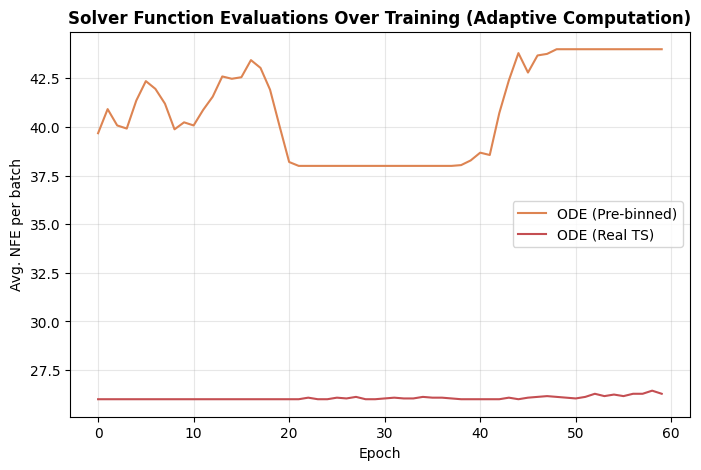

In [ ]:
fig2, ax = plt.subplots(figsize=(8, 5))
ax.plot(nfes['ode_b'], label='ODE (Pre-binned)', color='#DD8452')
ax.plot(nfes['ode_t'], label='ODE (Real TS)', color='#C44E52')
ax.set_xlabel('Epoch'); ax.set_ylabel('Avg. NFE per batch')
ax.set_title('Solver Function Evaluations Over Training (Adaptive Computation)', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
#plt.savefig('/kaggle/working/nfe_over_epochs.png', dpi=200, bbox_inches='tight')
plt.show()